In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm
import copy
import time
import math
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
Device: cuda
GPU: Tesla T4


In [2]:

transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="/kaggle/working/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="/kaggle/working/data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_full))
print("Test samples:", len(test_dataset))

image, label = train_full[0]

print("Image shape:", image.shape)
print("Label:", label)

100%|██████████| 9.91M/9.91M [00:00<00:00, 41.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.86MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 17.1MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5


In [3]:
train_dataset, val_dataset = random_split(
    train_full,
    [50000, 10000],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 50000
Validation: 10000
Test: 10000


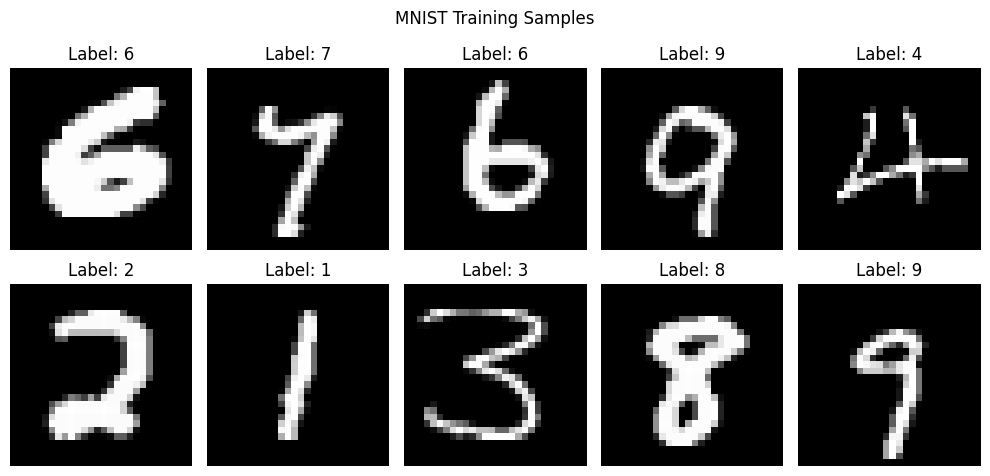

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.suptitle("MNIST Training Samples")
plt.tight_layout()
plt.show()

### Training loop

In [5]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        
        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * labels.size(0)
        
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size
    return total_loss / total, correct / total

In [6]:
def fit(model, train_loader, val_loader, epochs=10, lr=0.001, device="cuda", model_name="model"):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in tqdm(range(epochs), desc=f"Training {model_name}", leave=True):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            
        training_time = time.time() - start_time
        
    model.load_state_dict(best_weights)
    torch.save(
        model.state_dict(),
        f"/kaggle/working/{model_name}_best.pth"
    )

    return model, history, training_time

In [7]:
@torch.no_grad()
def evaluate(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

### My Multi-head Attention

In [8]:
class PatchEmbedding(nn.Module):
    def __init__(self, embed_dim=64, patch_size=7):
        super().__init__()
        self.num_tokens = (28 // patch_size) ** 2
        self.projection = nn.Conv2d(
            in_channels=1, 
            out_channels=embed_dim, 
            kernel_size=patch_size, 
            stride=patch_size
        )

    def forward(self,x):
        x = self.projection(x)
        x = x.flatten(2)
        x = x.transpose(1,2)
        return x

In [9]:
class RowEmbedding(nn.Module):
    def __init__(self, embed_dim=64):
        super().__init__()
        self.num_tokens = 28
        self.projection = nn.Linear(28,embed_dim)

    def forward(self, x):
        x = x.squeeze(1)
        x = self.projection(x)
        return x

In [10]:
class CNNEmbedding(nn.Module):
    def __init__(self, embed_dim=64):
        super().__init__()
        self.num_tokens = 49
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 256, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(256, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
    def forward(self, x):
        x = self.cnn(x)
        x = x.flatten(2)
        x = x.transpose(1,2)
        return x

In [11]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=64, num_heads=4):
        super().__init__()
        
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)

        self.out_proj = nn.Linear(embed_dim, embed_dim)
    def forward(self, x):
        B, N, D = x.shape
        
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        Q = Q.reshape(B, N, self.num_heads, self.head_dim).transpose(1, 2)
        K = K.reshape(B, N, self.num_heads, self.head_dim).transpose(1, 2)
        V = V.reshape(B, N, self.num_heads, self.head_dim).transpose(1, 2)

        scores = Q @ K.transpose(2,3)
        scores = scores / math.sqrt(self.head_dim)

        attention_weight = F.softmax(scores, dim=-1)

        context = attention_weight @ V

        context = context.transpose(1, 2).contiguous()
        context = context.reshape(B, N, D)

        output = self.out_proj(context)
        return output

### Pytorch Multi-head Attention

In [12]:
class PyTorchMSA(nn.Module):
    def __init__(self, embed_dim=64, num_heads=4):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            batch_first=True,
            dropout=0.0
        )

    def forward(self, x):
        output, _ = self.attention(
            x, x, x,
            need_weights=False
        )
        return output

### TransformerBlock

In [13]:
class TransformerBlock(nn.Module):
    def __init__(
        self,
        embed_dim=64,
        num_heads=4,
        mlp_ratio=2,
        attention_type="scratch"
    ):
        super().__init__()

        if attention_type == "scratch":
            self.attention = MultiHeadSelfAttention(
                embed_dim, num_heads
            )

        elif attention_type == "pytorch":
            self.attention = PyTorchMSA(
                embed_dim, num_heads
            )

        else:
            raise ValueError("Invalid attention_type")

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

        hidden_dim = int(embed_dim * mlp_ratio)

        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embed_dim)
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x

### MH-A Classifier

In [14]:
class TransformerClassifier(nn.Module):
    def __init__(
        self,
        tokenization="patch",
        attention_type="scratch",
        embed_dim=64,
        num_heads=4,
        num_layers=1,
        num_classes=10
    ):
        super().__init__()
        if tokenization == "patch":
            self.embedding = PatchEmbedding(
                embed_dim=embed_dim,
                patch_size=7
            )
        elif tokenization == "row":
            self.embedding = RowEmbedding(
                embed_dim=embed_dim
            )
        elif tokenization == "cnn":
            self.embedding = CNNEmbedding(
                embed_dim=embed_dim
            )
        else:
            raise ValueError("Invalid tokenization")

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                self.embedding.num_tokens,
                embed_dim
            )
        )
        nn.init.trunc_normal_(
            self.pos_embedding,
            std=0.02
        )

        self.blocks = nn.Sequential(
            *[
                TransformerBlock(
                    embed_dim=embed_dim,
                    num_heads=num_heads,
                    attention_type=attention_type
                )
                for _ in range(num_layers)
            ]
        )

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        x = self.embedding(x)
        x = x + self.pos_embedding
        x = self.blocks(x)
        # Mean Pooling trên các token N, D -> 1, D
        x = x.mean(dim=1)
        x = self.norm(x)
        logits = self.head(x)
        return logits

In [15]:
patch_scratch = TransformerClassifier(
    tokenization="patch",
    attention_type="scratch"
).to(device)

patch_scratch, patch_history, patch_time = fit(
    model=patch_scratch,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="patch_scratch"
)

Training patch_scratch:   0%|          | 0/10 [00:00<?, ?it/s]

In [16]:
row_scratch = TransformerClassifier(
    tokenization="row",
    attention_type="scratch"
).to(device)

row_scratch, row_history, row_time = fit(
    model=row_scratch,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="row_scratch"
)

Training row_scratch:   0%|          | 0/10 [00:00<?, ?it/s]

In [17]:
cnn_scratch = TransformerClassifier(
    tokenization="cnn",
    attention_type="scratch"
).to(device)

cnn_scratch, cnn_history, cnn_time = fit(
    model=cnn_scratch,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="cnn_scratch"
)

Training cnn_scratch:   0%|          | 0/10 [00:00<?, ?it/s]

In [18]:
pytorch_mha = TransformerClassifier(
    attention_type="pytorch"
).to(device)

pytorch_mha, pytorch_history, pytorch_time = fit(
    model=pytorch_mha,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    device=device,
    model_name="pytorch_mha"
)

Training pytorch_mha:   0%|          | 0/10 [00:00<?, ?it/s]

### Evaluation

In [19]:
criterion = nn.CrossEntropyLoss()

models = {
    "Patch_scratch": patch_scratch,
    "Row_scratch": row_scratch,
    "Cnn_scratch": cnn_scratch,
    "Pytorch": pytorch_mha
}

training_times = {
    "Patch_scratch": patch_time,
    "Row_scratch": row_time,
    "Cnn_scratch": cnn_time,
    "Pytorch": pytorch_time
}

for name, model in models.items():
    test_loss, test_acc = evaluate(
        model, test_loader, criterion, device
    )

    params = sum(
        p.numel() for p in model.parameters()
    )

    train_time = training_times[name]

    print(
        f"{name:15s} | "
        f"Accuracy: {test_acc*100:.2f}% | "
        f"Parameters: {params:,} | "
        f"Training Time: {train_time:.2f}s"
    )

Patch_scratch   | Accuracy: 96.80% | Parameters: 38,474 | Training Time: 77.39s
Row_scratch     | Accuracy: 97.76% | Parameters: 37,898 | Training Time: 75.18s
Cnn_scratch     | Accuracy: 98.65% | Parameters: 187,466 | Training Time: 117.02s
Pytorch         | Accuracy: 96.79% | Parameters: 38,474 | Training Time: 74.47s


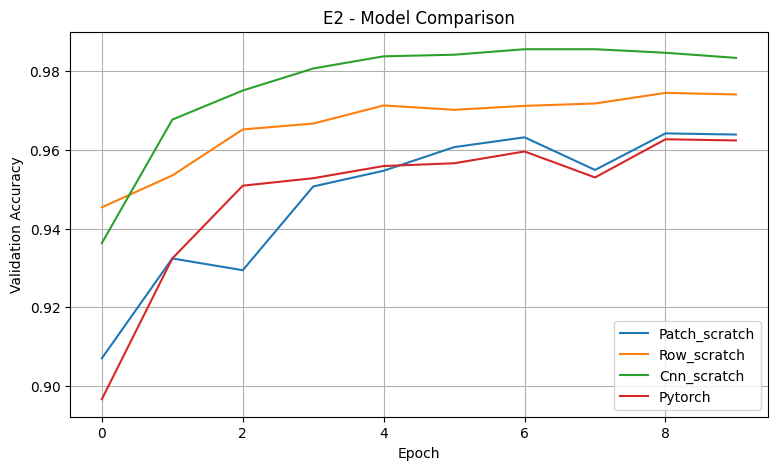

In [20]:
import matplotlib.pyplot as plt

histories = {
    "Patch_scratch": patch_history,
    "Row_scratch": row_history,
    "Cnn_scratch": cnn_history,
    "Pytorch": pytorch_history
}

plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(
        history["val_acc"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("E2 - Model Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

@torch.no_grad()
def plot_confusion_matrix(model, test_loader, device, model_name):
    model.eval()

    all_labels = []
    all_preds = []

    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

    cm = confusion_matrix(
        all_labels,
        all_preds,
        labels=list(range(10))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(range(10))
    )

    fig, ax = plt.subplots(figsize=(8, 7))
    disp.plot(ax=ax, cmap="Blues", values_format="d")

    ax.set_title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return np.array(all_labels), np.array(all_preds)

In [22]:
@torch.no_grad()
def show_misclassified(model, test_loader, device, model_name, n=10):
    model.eval()

    wrong_images = []
    wrong_labels = []
    wrong_preds = []
    wrong_probs = []

    for images, labels in test_loader:
        images_gpu = images.to(device)

        logits = model(images_gpu)
        probabilities = torch.softmax(logits, dim=1)

        predictions = probabilities.argmax(dim=1)
        confidence = probabilities.max(dim=1).values

        wrong_mask = predictions.cpu() != labels

        wrong_images.extend(images[wrong_mask])
        wrong_labels.extend(labels[wrong_mask].tolist())
        wrong_preds.extend(
            predictions.cpu()[wrong_mask].tolist()
        )
        wrong_probs.extend(
            confidence.cpu()[wrong_mask].tolist()
        )

    n = min(n, len(wrong_images))

    if n == 0:
        print(f"{model_name}: No misclassified images!")
        return

    fig, axes = plt.subplots(
        2, 5,
        figsize=(16, 8)
    )
    
    for i, ax in enumerate(axes.flat):
        if i < n:
            ax.imshow(wrong_images[i].squeeze(), cmap="gray")
    
            ax.set_title(
                f"True: {wrong_labels[i]} | Pred: {wrong_preds[i]}\n"
                f"Confidence: {wrong_probs[i]*100:.1f}%",
                fontsize=11,
                pad=12
            )
    
        ax.axis("off")
    
    plt.suptitle(
        f"{model_name} - Misclassified Images",
        fontsize=16,
        y=0.98
    )
    
    plt.subplots_adjust(
        hspace=0.65,  
        wspace=0.20,  
        top=0.85
    )
    
    plt.show()

    print(f"Total misclassified images: {len(wrong_images)}")


Model: Patch_scratch


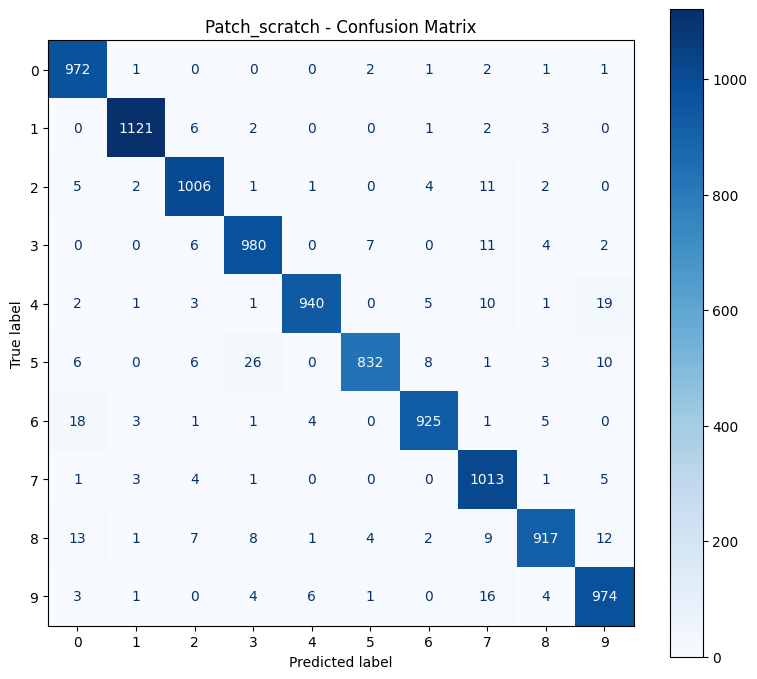

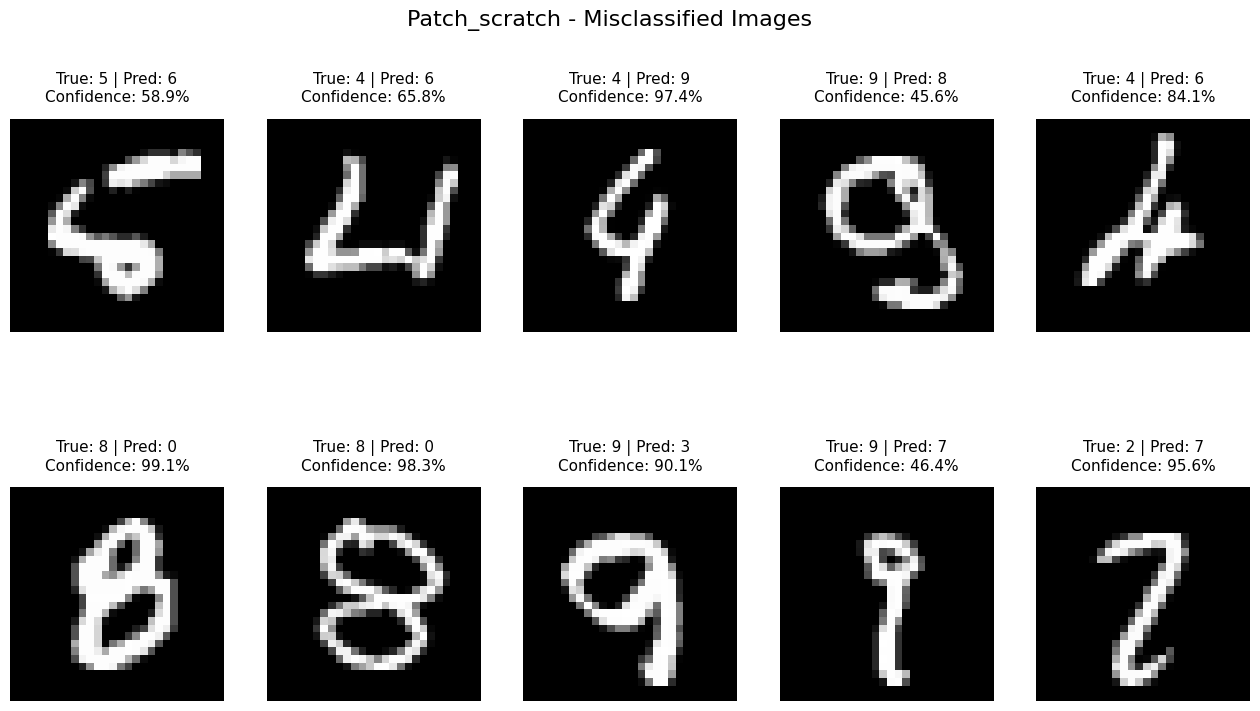

Total misclassified images: 320

Model: Row_scratch


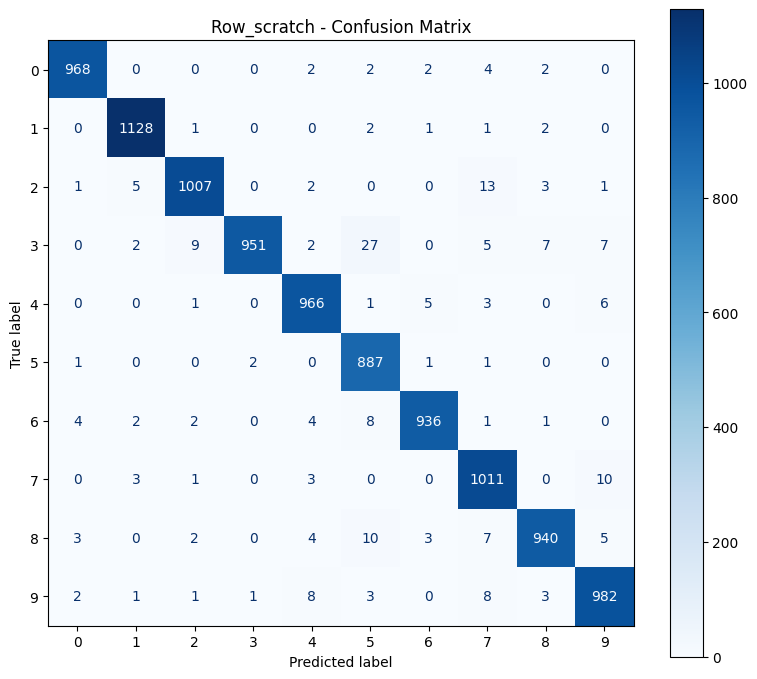

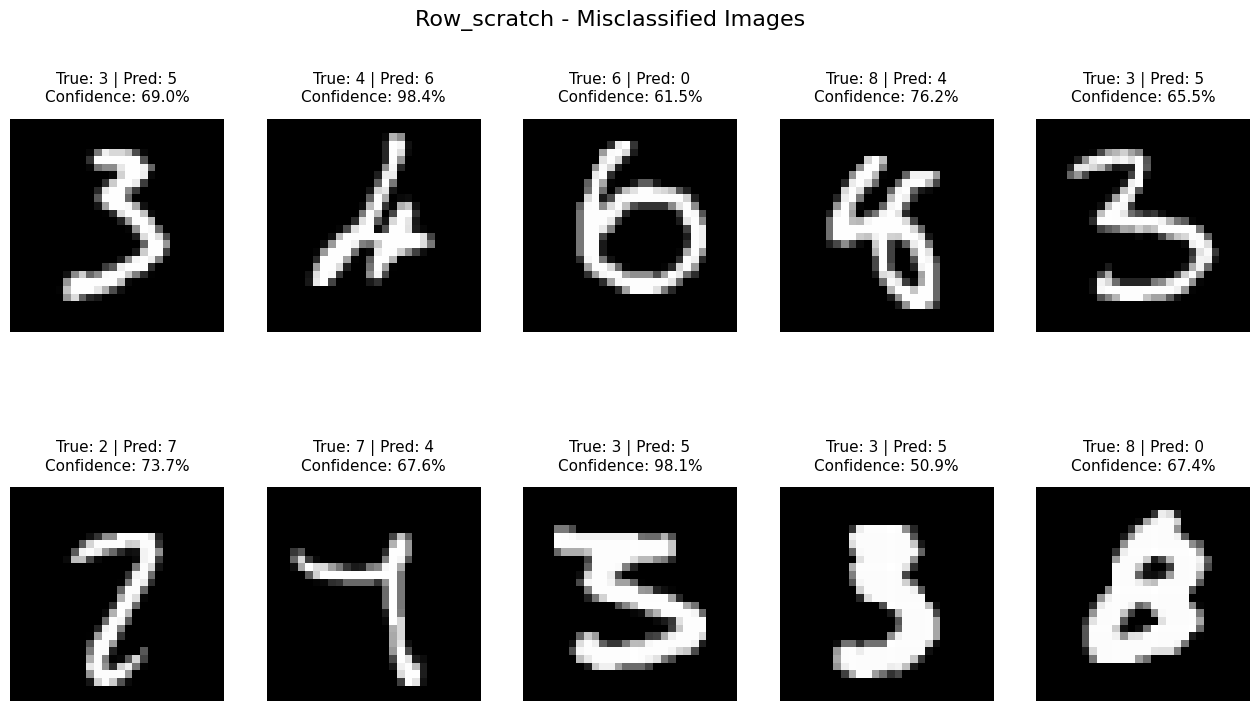

Total misclassified images: 224

Model: Cnn_scratch


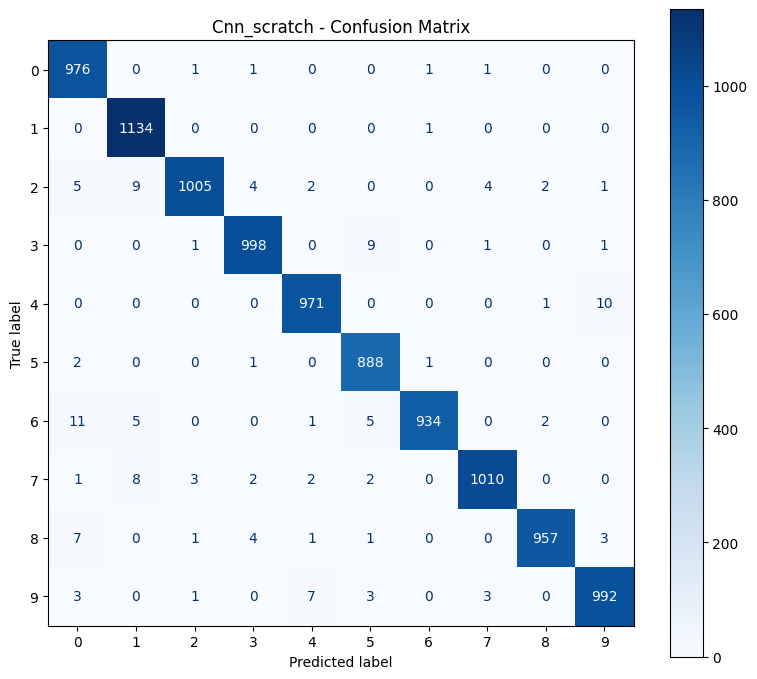

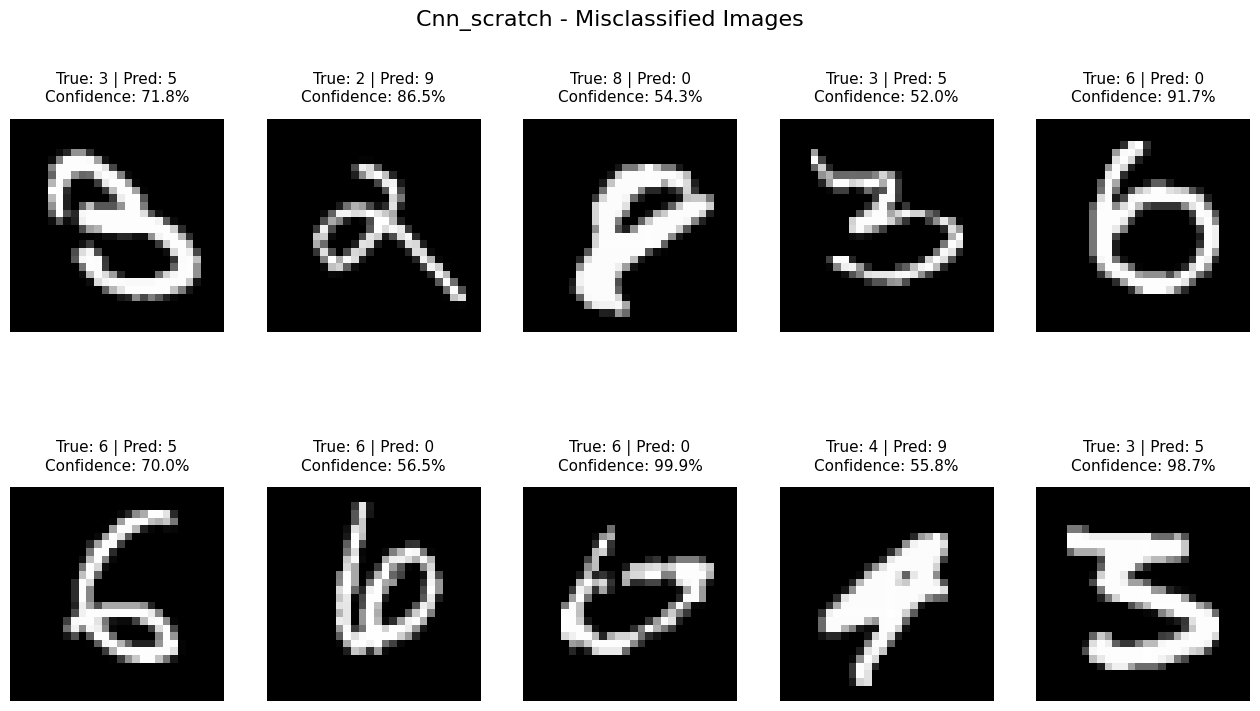

Total misclassified images: 135

Model: Pytorch


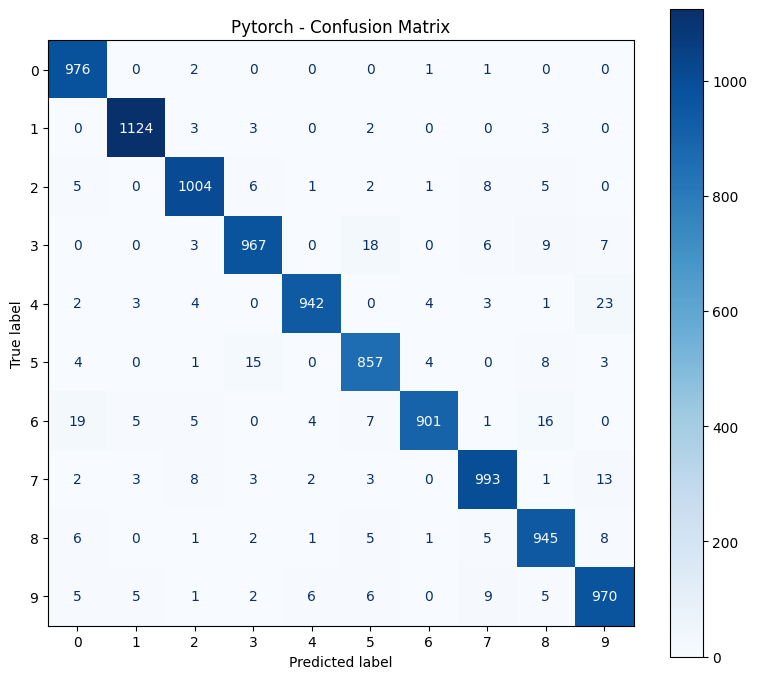

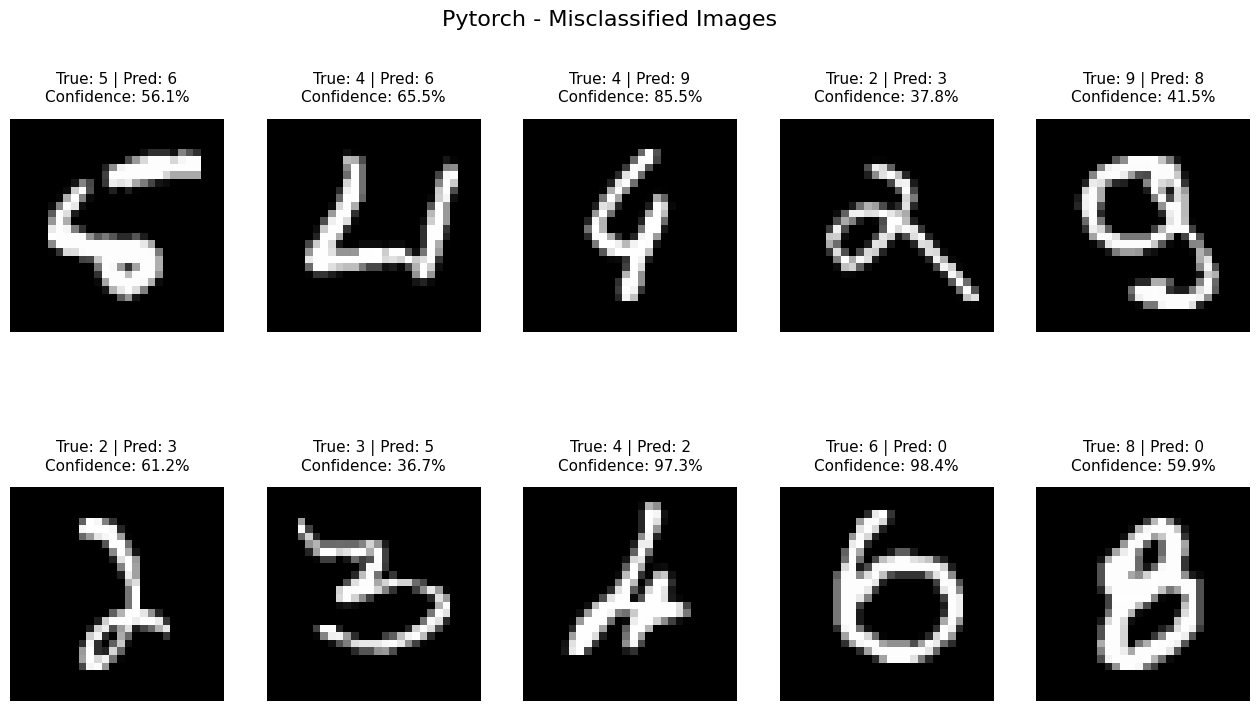

Total misclassified images: 321


In [23]:
models = {
    "Patch_scratch": patch_scratch,
    "Row_scratch": row_scratch,
    "Cnn_scratch": cnn_scratch,
    "Pytorch": pytorch_mha
}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Model: {name}")
    print(f"{'='*50}")

    # 1. Confusion Matrix
    true_labels, pred_labels = plot_confusion_matrix(
        model,
        test_loader,
        device,
        name
    )

    # 2. Misclassified Images
    show_misclassified(
        model,
        test_loader,
        device,
        name,
        n=10
    )